# Hypothesis Testing for EDA

**Notebook 4 of 5.** `03_how_a_test_works.ipynb` took one test apart until every step made
sense: hypotheses, a test statistic, a p-value, a decision. This notebook puts the same five
steps to work where you will need them most.

Exploratory data analysis is full of moments where a plot suggests a pattern: one group looks bigger, two variables seem related, a category looks over-represented. Hypothesis testing is how you check whether such a pattern is more than noise before you report it or build on it.

A correlation coefficient, Cramér's V or the correlation ratio measures how *strong* a pattern is. A test adds the question those numbers cannot answer: whether the pattern could be chance. This notebook works through one EDA session on a real dataset. For each type of variable pair we make the plot, quantify the pattern, and run the matching test. Along the way you will see both outcomes: patterns that survive testing and patterns that do not.

## Learning Objectives

At the end of this notebook, you should be able to:

- Select the matching hypothesis test for each variable-pair type met during EDA.
- Test numeric-numeric, categorical-numeric, and categorical-categorical associations with scipy.
- Combine a plot, an effect size, and a p-value into one conclusion about a pattern.
- Recognise the multiple-testing trap that exploratory analysis creates, and report exploratory findings honestly.

## Which test for which pair?

During EDA every question is about a pair of variables, and the pair type picks the test,
just as it picks the measure of strength:

| Pair of columns | Test | scipy function | Effect size to report with it |
| :--- | :--- | :--- | :--- |
| numeric vs numeric | Pearson or Spearman correlation | `pearsonr`, `spearmanr` | the correlation coefficient |
| categorical with **two** groups vs numeric | Welch's t-test, or Mann-Whitney U | `ttest_ind`, `mannwhitneyu` | the difference in means |
| categorical with **three or more** groups vs numeric | one-way ANOVA | `f_oneway` | the correlation ratio |
| categorical vs categorical | chi-square test of independence | `chi2_contingency` | Cramér's V |

Every one of them follows the five steps from notebook 03. Only the test statistic and the
curve it is compared with change, and those curves are the three from section 5 of
notebook 01: correlation and t-tests compare against a t-distribution, ANOVA against F, and
the chi-square test against chi-square. Mann-Whitney U works on ranks instead, and scipy
handles its curve for you. Each section below takes one row of this table.

## The data

We use the classic `tips` dataset: 244 restaurant bills with the bill amount, the tip, and who paid it (sex, smoker, day, time of day). It is saved in `data/tips.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

df = pd.read_csv("data/tips.csv")

# a CSV stores categories as plain text, so restore their natural order:
# otherwise pandas sorts the days alphabetically, Fri, Sat, Sun, Thur
df["day"] = pd.Categorical(df["day"], categories=["Thur", "Fri", "Sat", "Sun"], ordered=True)
df["time"] = pd.Categorical(df["time"], categories=["Lunch", "Dinner"], ordered=True)

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
# Tip percentage is often more informative than the raw tip,
# because bigger bills mechanically produce bigger tips
df["tip_pct"] = df["tip"] / df["total_bill"] * 100
df.describe()

,total_bill,tip,size,tip_pct
count,244.000000,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672,16.080258
std,8.902412,1.383638,0.951100,6.107220
min,3.070000,1.000000,1.000000,3.563814
25%,13.347500,2.000000,2.000000,12.912736
50%,17.795000,2.900000,2.000000,15.476977
75%,24.127500,3.562500,3.000000,19.147549
max,50.810000,10.000000,6.000000,71.034483


---
## 1. Numeric vs Numeric: Correlation

**EDA question:** do larger bills come with larger tips?

The plot for this pair type is a scatter plot; the effect size is the correlation coefficient; the test asks whether that coefficient could plausibly be zero.

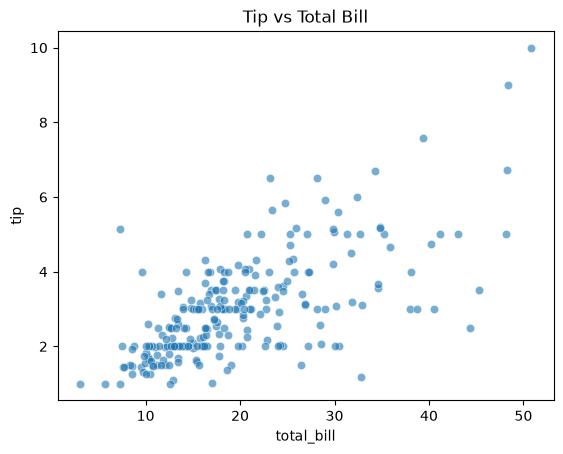

In [3]:
sns.scatterplot(data=df, x="total_bill", y="tip", alpha=0.6)
plt.title("Tip vs Total Bill")
plt.show()

In [4]:
# Pearson measures the strength of a linear relationship;
# its H0 is that the true correlation is zero
r, p_value = stats.pearsonr(df["total_bill"], df["tip"])
print(f"Pearson r: {r:.3f}, p-value: {p_value:.2e}")

Pearson r: 0.676, p-value: 6.69e-34


The scatter plot shows a clear upward drift, and the numbers agree: r = 0.68, a strong positive correlation, with a p-value around 1e-33. With 244 points, a correlation this strong is essentially impossible under independence, so this pattern is real.

The alternative: **Spearman correlation** (`stats.spearmanr`) ranks the data first, so it is robust to outliers and captures any monotonic (not just linear) relationship. Here it gives almost the same answer (0.68), which tells us the linear story is not driven by a few extreme bills.

One caution that no test removes: correlation is not causation. The bill does not cause the tip by itself; party size drives both.

---
## 2. Categorical vs Numeric, Two Groups: t-test

**EDA question:** are dinner bills larger than lunch bills?

The plot is a box plot per group; the effect size is the difference in group means; the test is a two-sample t-test.

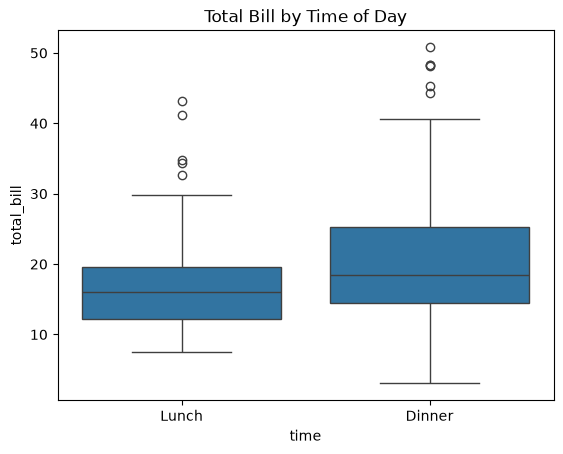

,count,mean,std
time,,,
Lunch,68,17.168676,7.713882
Dinner,176,20.797159,9.142029


In [5]:
sns.boxplot(data=df, x="time", y="total_bill")
plt.title("Total Bill by Time of Day")
plt.show()

df.groupby("time", observed=True)["total_bill"].agg(["count", "mean", "std"])

### Check the assumptions first

The t-test assumes roughly normal data within each group. Bills are money amounts, and money is usually right-skewed, so we check before trusting the test.

In [6]:
lunch = df[df["time"] == "Lunch"]["total_bill"]
dinner = df[df["time"] == "Dinner"]["total_bill"]

# Shapiro-Wilk: H0 is that the data is normal
print(f"Shapiro p-value (lunch):  {stats.shapiro(lunch)[1]:.2e}")
print(f"Shapiro p-value (dinner): {stats.shapiro(dinner)[1]:.2e}")

# Levene: H0 is that the two groups have equal variances
print(f"Levene p-value: {stats.levene(lunch, dinner)[1]:.3f}")

Shapiro p-value (lunch):  3.64e-06
Shapiro p-value (dinner): 2.69e-07
Levene p-value: 0.102


Shapiro-Wilk rejects normality for both groups (p-values around 1e-06): the bills are right-skewed, as expected. That is not fatal here, because with 68 and 176 observations the central limit theorem from notebook 02 makes the sampling distribution of each group's average approximately normal anyway. But it is a reason to double-check with a test that does not assume normality, which we do below.

We use **Welch's t-test** (`equal_var=False`), which does not assume equal variances. Levene's test did not reject equal variances (p = 0.10), but Welch costs almost nothing when variances are equal and protects you when they are not, so it is the sensible default.

In [7]:
# Welch's t-test: H0 is that lunch and dinner have the same mean bill
t_stat, p_value = stats.ttest_ind(lunch, dinner, equal_var=False)
print(f"Welch t-statistic: {t_stat:.3f}, p-value: {p_value:.5f}")

# Robustness check without the normality assumption:
# Mann-Whitney U compares the two distributions via ranks
u_stat, p_mw = stats.mannwhitneyu(lunch, dinner)
print(f"Mann-Whitney U p-value: {p_mw:.5f}")

Welch t-statistic: -3.123, p-value: 0.00217
Mann-Whitney U p-value: 0.00118


Dinner bills average about 20.80 against 17.17 at lunch, and the Welch t-test gives p = 0.002: the difference is significant. The Mann-Whitney U test, which does not assume normality at all, agrees (p = 0.001). When a parametric test and its non-parametric alternative point the same way, the conclusion is solid: people spend more at dinner.

### A pattern that does not survive: tip percentage

Raw bills differ by time of day. Does the tipping *rate* differ too? The group means look slightly different, which is exactly the kind of pattern EDA tempts you to report.

In [8]:
lunch_pct = df[df["time"] == "Lunch"]["tip_pct"]
dinner_pct = df[df["time"] == "Dinner"]["tip_pct"]
print(f"Mean tip %: lunch {lunch_pct.mean():.2f}, dinner {dinner_pct.mean():.2f}")

t_stat, p_value = stats.ttest_ind(lunch_pct, dinner_pct, equal_var=False)
print(f"Welch t-statistic: {t_stat:.3f}, p-value: {p_value:.3f}")

Mean tip %: lunch 16.41, dinner 15.95
Welch t-statistic: 0.654, p-value: 0.514


Lunch guests tip 16.4% on average against 16.0% at dinner, but the p-value is 0.51: a difference this small is entirely consistent with chance. This is the lesson of the whole notebook in one line: **the plot proposes, the test disposes.** Dinner produces bigger bills and bigger tips, but not more generous tippers.

---
## 3. Categorical vs Numeric, More Than Two Groups: ANOVA

**EDA question:** does the average bill depend on the day of the week?

With four groups (Thursday to Sunday), running t-tests on every pair would mean six tests and six chances of a false positive. **One-way ANOVA** asks a single question instead: are all group means equal? Its H0 is that every day has the same mean bill. Its test statistic, **F**, compares how far apart the group means are with how spread out the bills are inside each group, and its p-value is an area under the F curve from notebook 01.

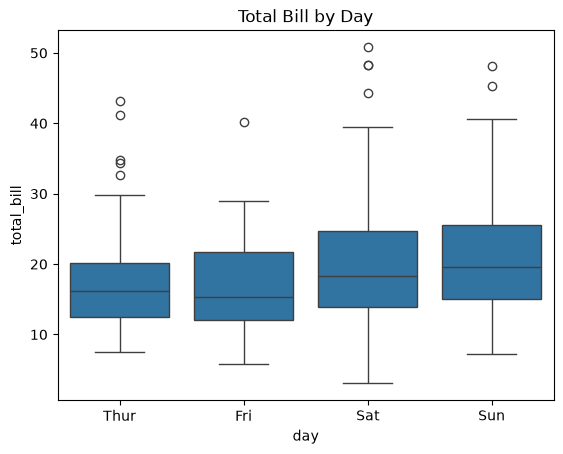

day
Thur    17.68
Fri     17.15
Sat     20.44
Sun     21.41
Name: total_bill, dtype: float64

In [9]:
sns.boxplot(data=df, x="day", y="total_bill")
plt.title("Total Bill by Day")
plt.show()

df.groupby("day", observed=True)["total_bill"].mean().round(2)

In [10]:
# One-way ANOVA across the four days
groups = [g["total_bill"].values for _, g in df.groupby("day", observed=True)]
f_stat, p_value = stats.f_oneway(*groups)
print(f"ANOVA F-statistic: {f_stat:.3f}, p-value: {p_value:.4f}")

# Same question for the tipping rate
groups_pct = [g["tip_pct"].values for _, g in df.groupby("day", observed=True)]
f_stat2, p_value2 = stats.f_oneway(*groups_pct)
print(f"ANOVA on tip %: F-statistic: {f_stat2:.3f}, p-value: {p_value2:.3f}")

ANOVA F-statistic: 2.767, p-value: 0.0425
ANOVA on tip %: F-statistic: 0.848, p-value: 0.469


For the bill amount, ANOVA gives p = 0.043: just under 0.05, driven by the weekend days (Saturday 20.44 and Sunday 21.41 versus about 17.50 on Thursday and Friday). Treat a borderline p-value like this as a lead, not a verdict; section 5 explains why.

For the tip percentage the answer is clear the other way: p = 0.47. The tipping rate is flat across the week.

The follow-up: a significant ANOVA says "at least one day differs" but not which one. Answering that requires post-hoc pairwise tests with a multiple-comparison correction (for example Tukey's HSD, in the `statsmodels` library, which this repository does not install), not a pile of uncorrected t-tests.

---
## 4. Categorical vs Categorical: Chi-Square Test of Independence

**EDA question:** are smokers over-represented at dinner?

The plot is a grouped count plot; the summary is a contingency table; the test is the **chi-square test of independence**, whose H0 is that the two variables are unrelated. Its statistic measures how far the observed counts sit from the counts expected if they were, and its p-value is an area under the chi-square curve from notebook 01.

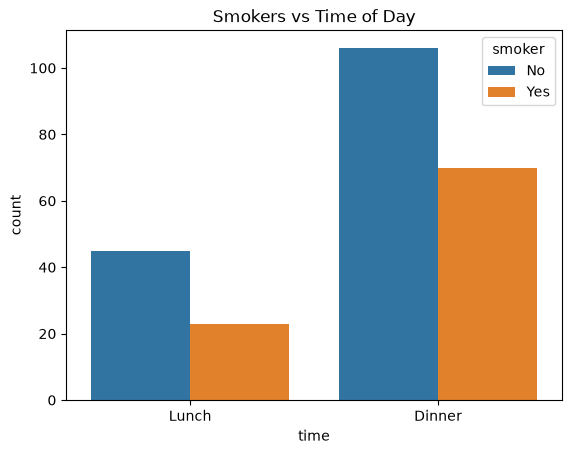

time,Lunch,Dinner
smoker,,
No,45,106
Yes,23,70


In [11]:
sns.countplot(data=df, x="time", hue="smoker")
plt.title("Smokers vs Time of Day")
plt.show()

contingency_table = pd.crosstab(df["smoker"], df["time"])
contingency_table

In [12]:
chi2_stat, p_value, dof, expected_freq = stats.chi2_contingency(contingency_table)
print(f"Chi-square statistic: {chi2_stat:.3f}, p-value: {p_value:.4f}, dof: {dof}")

# Cramer's V: effect size for a contingency table, from 0 (none) to 1 (perfect)
n = contingency_table.to_numpy().sum()
cramers_v = np.sqrt(chi2_stat / (n * (min(contingency_table.shape) - 1)))
print(f"Cramer's V: {cramers_v:.3f}")

Chi-square statistic: 0.505, p-value: 0.4771, dof: 1
Cramer's V: 0.046


The p-value is 0.48 and Cramér's V is 0.05, an effect size close to zero: smoking and time of day are unrelated in this data. The count plot can look lopsided only because there are more dinner bills overall; the chi-square test compares the observed counts with the frequencies expected from the margins, so it is not fooled by group sizes.

Reporting both numbers matters. The p-value says whether an association exists; **Cramér's V** says how strong it would be. With a big enough sample even a trivial association becomes "significant", so an effect size keeps the conclusion honest.

---
## 5. The EDA Trap: Multiple Testing

This notebook ran seven hypothesis tests. At alpha = 0.05, each test run on pure noise has a 5% chance of a false positive, so the chance of at least one false alarm grows quickly with every extra comparison: EDA is exactly the setting where you test many patterns because the plots invited you to.

That is why the borderline day-of-week result (p = 0.043) deserves scepticism: it was one of several comparisons, and it would not survive even a mild multiple-testing correction (a Bonferroni correction across our seven tests would demand p < 0.007).

Practical rules for testing during EDA:

- **Count your tests.** Note every test you run, including the ones that "didn't work".
- **Correct or confirm.** Either apply a multiple-comparison correction (Bonferroni, Holm), or treat exploratory findings as hypotheses to confirm on new data.
- **Report effect sizes with p-values.** A p-value alone hides whether the effect is worth caring about.
- **Never hunt for p < 0.05.** Testing subgroup after subgroup until something is significant is p-hacking, and its findings do not replicate.

---
## Summary

In this notebook you:

- Selected the matching test for each variable-pair type met during EDA.
- Tested a numeric-numeric pattern with a Pearson correlation test (tip vs bill: r = 0.68, p about 1e-33, real).
- Tested two-group differences with Welch's t-test and confirmed with Mann-Whitney U (dinner bills larger, p = 0.002; tip percentage unchanged, p = 0.51).
- Compared four groups at once with one-way ANOVA (bills by day: borderline p = 0.043; tip percentage: p = 0.47).
- Tested a categorical association with chi-square plus Cramér's V (smoker vs time: p = 0.48, V = 0.05, none).
- Applied the multiple-testing rules that keep exploratory findings honest.

| EDA question | Pair type | Test | p-value | Verdict |
|---|---|---|---|---|
| Bigger bills, bigger tips? | numeric vs numeric | Pearson correlation | 1e-33 | Real |
| Dinner bills larger? | categorical (2) vs numeric | Welch t-test | 0.002 | Real |
| Dinner tippers more generous? | categorical (2) vs numeric | Welch t-test | 0.51 | Not supported |
| Bills differ by day? | categorical (4) vs numeric | One-way ANOVA | 0.043 | Borderline lead |
| Smokers prefer dinner? | categorical vs categorical | Chi-square | 0.48 | Not supported |

Next, `05_hypothesis_testing_for_eda_exercise.ipynb` hands you a messier dataset and the same questions, without the worked answers.

## References & Further Reading

- [**scipy.stats.pearsonr**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html): Correlation coefficient with a significance test.
- [**scipy.stats.ttest_ind**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html): Independent two-sample t-test (`equal_var=False` for Welch).
- [**scipy.stats.mannwhitneyu**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html): The rank-based alternative to the t-test.
- [**scipy.stats.f_oneway**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html): One-way ANOVA.
- [**scipy.stats.chi2_contingency**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html): Chi-square test of independence.
- [**Statistical Hypothesis Analysis in Python with ANOVAs, Chi-Square, and Pearson Correlation**](https://stackabuse.com/statistical-hypothesis-analysis-in-python-with-anovas-chi-square-and-pearson-correlation/): The same three test families worked on another dataset.
- [**Codecademy: Testing an Association cheat sheet**](https://www.codecademy.com/learn/hypothesis-testing-python/modules/hp-testing-an-association/cheatsheet): One-page recap of which test fits which pair.
- [**StatQuest: P-hacking**](https://www.youtube.com/watch?v=HDCOUXE3HMM): Why the multiple-testing rules in section 5 exist.